# 12.3. Gradient Descent

In [23]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import torch
import math

### 1. Taylor expansion

In [7]:
def sin(x):
    return math.sin(x)

def taylor_sin(x, n):
    return sum((-1)**k * x**(2*k + 1) / math.factorial(2*k + 1) for k in range(n))

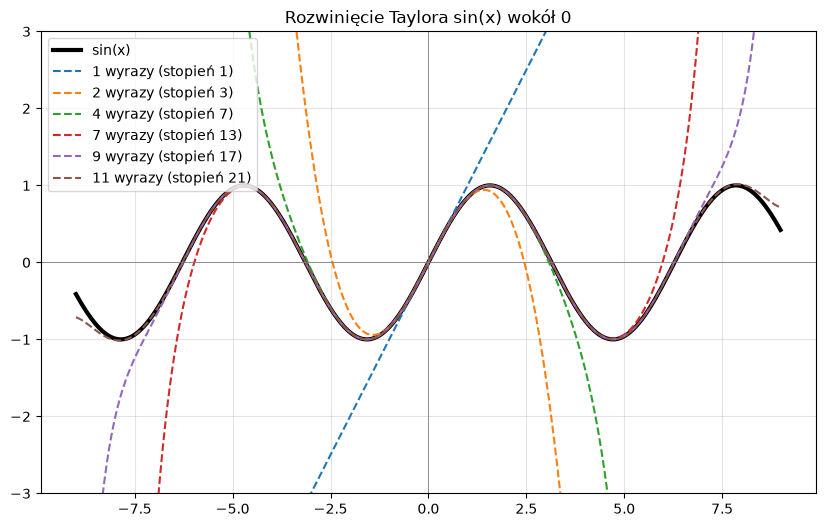

In [8]:
x_vals = np.arange(-9, 9, 0.01)
y_vals = np.array([sin(x) for x in x_vals])

plt.figure(figsize=(10, 6))
plt.plot(x_vals, y_vals, 'k', lw=3, label='sin(x)')
for n in [1, 2, 4, 7, 9, 11]:
    plt.plot(x_vals, taylor_sin(x_vals, n), '--', label=f'{n} wyrazy (stopień {2*n - 1})')
plt.ylim(-3, 3)
plt.axhline(0, color='gray', lw=0.6)
plt.axvline(0, color='gray', lw=0.6)
plt.grid(alpha=0.35)
plt.legend()
plt.title('Rozwinięcie Taylora sin(x) wokół 0')
plt.show()

### 12.3.1. One-Dimensional Gradient Descent

epoch 10, x: 0.060466


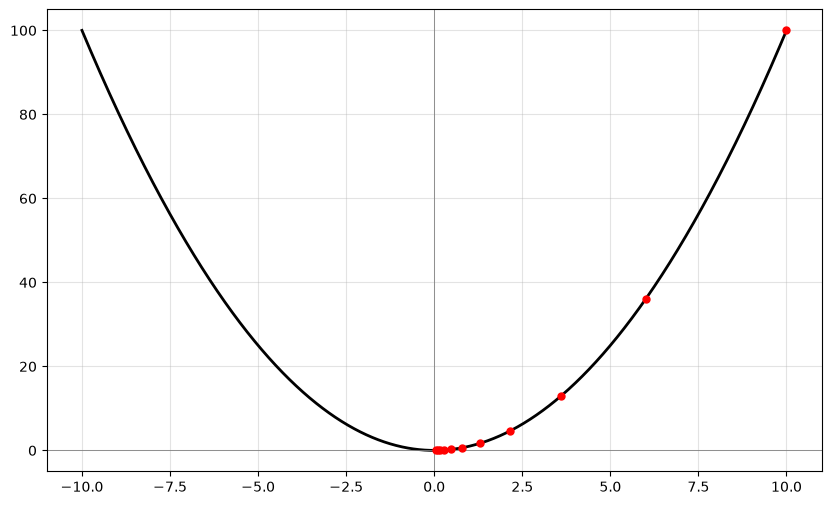

In [9]:
def f(x):  # Objective function
    return x ** 2

def f_grad(x):  # Gradient (derivative) of the objective function
    return 2 * x

def gd(eta, f_grad):
    x = 10.0
    results = [x]
    for i in range(10):
        x -= eta * f_grad(x)
        results.append(float(x))
    print(f'epoch 10, x: {x:f}')
    return results

results = gd(0.2, f_grad)

x_vals = np.arange(-10, 10, 0.01)
y_vals = np.array(x_vals**2)
plt.figure(figsize=(10, 6))
plt.plot(x_vals, y_vals, 'k', lw=2, label='x^2')
plt.axvline(0, color='gray', lw=0.6)
plt.axhline(0, color='gray', lw=0.6)
plt.grid(alpha=0.35)
plt.plot(results, [f(x) for x in results], '.', ms=10, color='red')

epoch 10, x: 0.000000


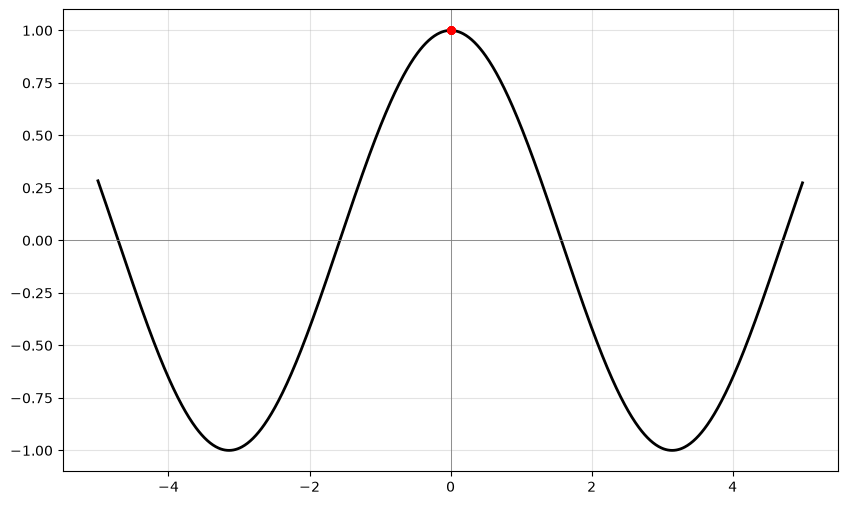

In [10]:
def cos(x):
    return math.cos(x)

def cos_grad(x):
    return -math.sin(x)

def gd_cos(eta, cos_grad):
    x = 0
    results = [x]
    for i in range(10):
        x -= eta * cos_grad(x)
        results.append(float(x))
    print(f'epoch 10, x: {x:f}')
    return results

x_vals = np.arange(-5, 5, 0.01)
y_vals = np.array([cos(x) for x in x_vals])

plt.figure(figsize=(10, 6))
plt.plot(x_vals, y_vals, 'k', lw=2, label='cos(x)')

plt.axvline(0, color='gray', lw=0.6)
plt.axhline(0, color='gray', lw=0.6)
plt.grid(alpha=0.35)

results = gd_cos(0.2, cos_grad)
plt.plot(results, [cos(x) for x in results], '.', ms=10, color='red')

### 12.3.1.1. Learning Rate

epoch 10, x: 3.486784


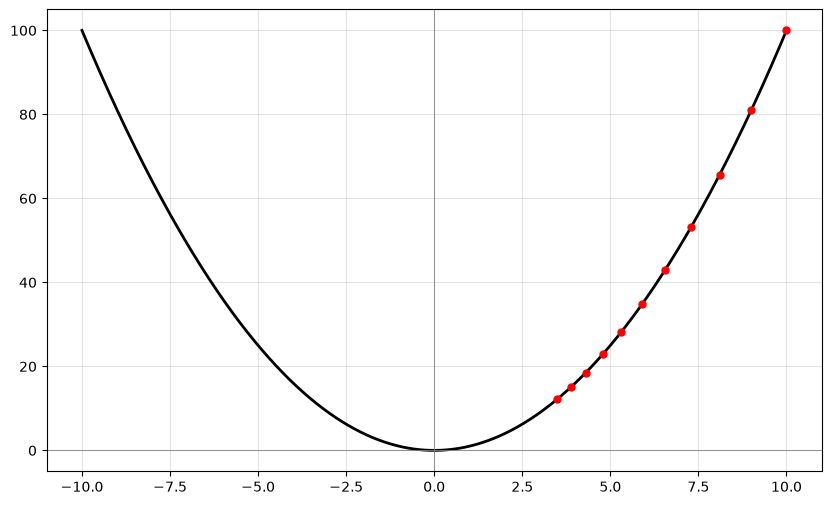

In [11]:
results = gd(0.05, f_grad)

x_vals = np.arange(-10, 10, 0.01)
y_vals = np.array(x_vals**2)
plt.figure(figsize=(10, 6))
plt.plot(x_vals, y_vals, 'k', lw=2, label='x^2')
plt.axvline(0, color='gray', lw=0.6)
plt.axhline(0, color='gray', lw=0.6)
plt.grid(alpha=0.35)
plt.plot(results, [f(x) for x in results], '.', ms=10, color='red')

epoch 10, x: 1.073742


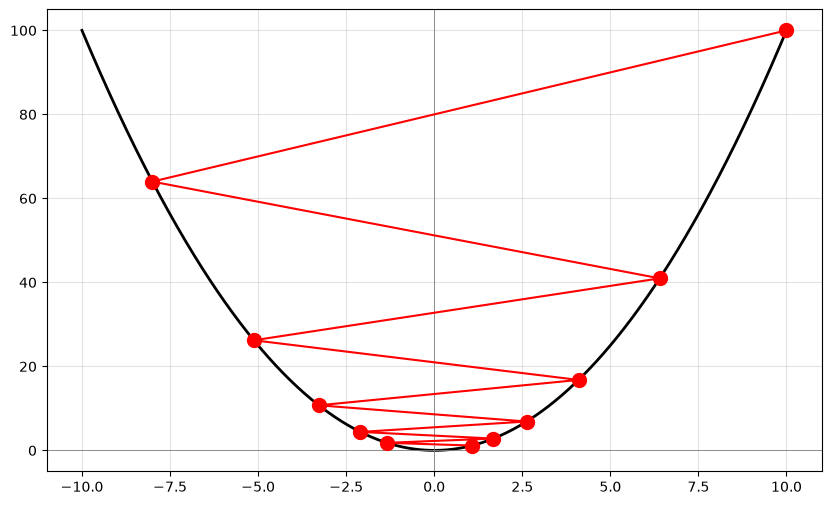

In [21]:
results = gd(0.9, f_grad)

x_vals = np.arange(-10, 10, 0.01)
y_vals = np.array(x_vals**2)
plt.figure(figsize=(10, 6))
plt.plot(x_vals, y_vals, 'k', lw=2, label='x^2')
plt.axvline(0, color='gray', lw=0.6)
plt.axhline(0, color='gray', lw=0.6)
plt.grid(alpha=0.35)
plt.plot(results, [f(x) for x in results], '-o', ms=10, color='red')

### 12.3.1.2. Local Minima

epoch 10, x: -1.528166


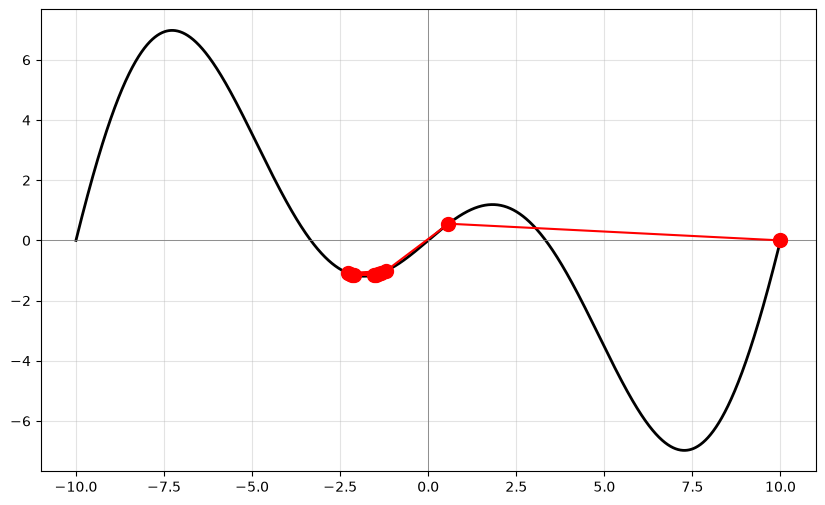

In [28]:
c = torch.tensor(0.15 * np.pi)

def f(x):  # Objective function
    return x * torch.cos(c * x)

def f_grad(x):  # Gradient of the objective function
    return torch.cos(c * x) - c * x * torch.sin(c * x)

results = gd(2, f_grad)

x_vals = np.arange(-10, 10, 0.01)
y_vals = np.array([f(x) for x in x_vals])
plt.figure(figsize=(10, 6))
plt.plot(x_vals, y_vals, 'k', lw=2, label='x^2')
plt.axvline(0, color='gray', lw=0.6)
plt.axhline(0, color='gray', lw=0.6)
plt.grid(alpha=0.35)
plt.plot(results, [f(x) for x in results], '-o', ms=10, color='red')

### 12.3.2. Multivariate Gradient Descent

In [29]:
def train_2d(trainer, steps=20, f_grad=None):  #@save
    """Optimize a 2D objective function with a customized trainer."""
    # `s1` and `s2` are internal state variables that will be used in Momentum, adagrad, RMSProp
    x1, x2, s1, s2 = -5, -2, 0, 0
    results = [(x1, x2)]
    for i in range(steps):
        if f_grad:
            x1, x2, s1, s2 = trainer(x1, x2, s1, s2, f_grad)
        else:
            x1, x2, s1, s2 = trainer(x1, x2, s1, s2)
        results.append((x1, x2))
    print(f'epoch {i + 1}, x1: {float(x1):f}, x2: {float(x2):f}')
    return results

def show_trace_2d(f, results):  #@save
    """Show the trace of 2D variables during optimization."""
    plt.figure(figsize=(10, 6))
    plt.plot(*zip(*results), '-o', color='#ff7f0e')
    x1, x2 = torch.meshgrid(torch.arange(-5.5, 1.0, 0.1),
                          torch.arange(-3.0, 1.0, 0.1), indexing='ij')
    plt.contour(x1, x2, f(x1, x2), colors='#1f77b4')
    plt.xlabel('x1')
    plt.ylabel('x2')

epoch 20, x1: -0.057646, x2: -0.000073


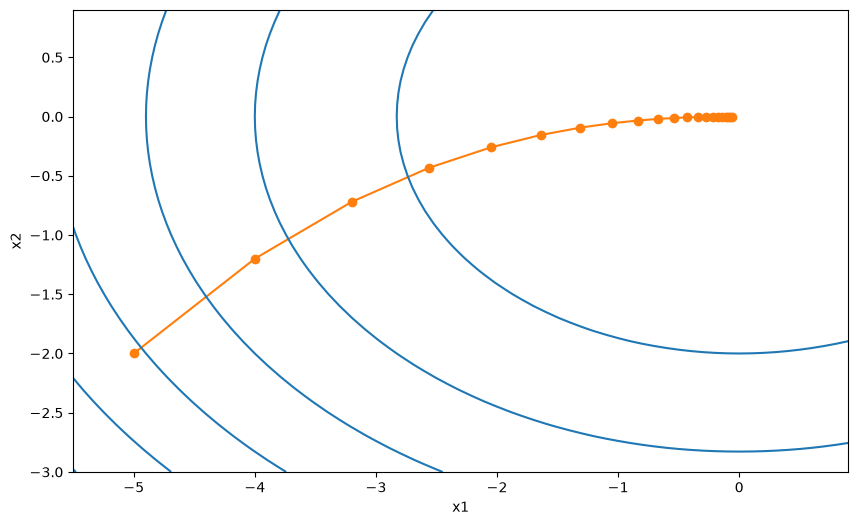

In [31]:
def f_2d(x1, x2):  # Objective function
    return x1 ** 2 + 2 * x2 ** 2

def f_2d_grad(x1, x2):  # Gradient of the objective function
    return (2 * x1, 4 * x2)

def gd_2d(x1, x2, s1, s2, f_grad):
    g1, g2 = f_grad(x1, x2)
    return (x1 - eta * g1, x2 - eta * g2, 0, 0)

eta = 0.1
show_trace_2d(f_2d, train_2d(gd_2d, f_grad=f_2d_grad))